In [25]:
TRAIN_PATH = r"data/split/train.csv"       # your training split (2017-2023)
VAL_PATH   = r"data/split/validation.csv"         # your validation split (2024); set to None to skip                    # figures and the quality table are saved here
TEST_START_SEASON = 2025                   # first test season; any row at or after it is refused

In [26]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

REQUIRED = ["match_id", "season", "over", "balls_left", "runs_needed", "wickets_lost",
            "required_run_rate", "current_run_rate", "target", "chasing_team_won",
            "venue", "city"]

def load(path, name):
    df = pd.read_csv(path)
    missing = [c for c in REQUIRED if c not in df.columns]
    assert not missing, f"{name} file is missing columns: {missing}"
    assert df.season.max() < TEST_START_SEASON, (
        f"{name} file contains season {df.season.max()}, which is a test season "
        f"(>= {TEST_START_SEASON}). EDA must not use test data - check the path.")
    df["split"] = name
    return df

train = load(TRAIN_PATH, "train")
parts = [train] + ([load(VAL_PATH, "val")] if VAL_PATH else [])
df = pd.concat(parts, ignore_index=True)

print(df.split.value_counts().to_string())
print("Seasons:", sorted(int(s) for s in df.season.unique()))
df.head()

split
train    17578
val       1239
Seasons: [2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


,match_id,date,season,venue,city,batting_team,bowling_team,toss_won_by_chaser,target,chasing_team_won,over,runs_so_far,wickets_lost,balls_left,runs_needed,current_run_rate,required_run_rate,runs_last_3,wkts_last_3,split
0,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,1,208,0,1,11,0,114,197,11.000000,10.368421,11,0,train
1,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,1,208,0,2,12,0,108,196,6.000000,10.888889,12,0,train
2,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,1,208,0,3,28,0,102,180,9.333333,10.588235,28,0,train
3,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,1,208,0,4,43,0,96,165,10.750000,10.312500,32,0,train
4,1082591,2017-04-05,2017,"Rajiv Gandhi International Stadium, Uppal",Hyderabad,Royal Challengers Bengaluru,Sunrisers Hyderabad,1,208,0,5,48,0,90,160,9.600000,10.666667,36,0,train


In [27]:
m = df.groupby("match_id").agg(season=("season", "first"), target=("target", "first"),
                               won=("chasing_team_won", "first"), split=("split", "first"),
                               n_rows=("over", "size"))
print(m.groupby("split").agg(matches=("won", "size"), chase_win_rate=("won", "mean"),
                             mean_target=("target", "mean")).round(3).to_string())

       matches  chase_win_rate  mean_target
split                                      
train      977           0.542      165.758
val         70           0.514      191.057


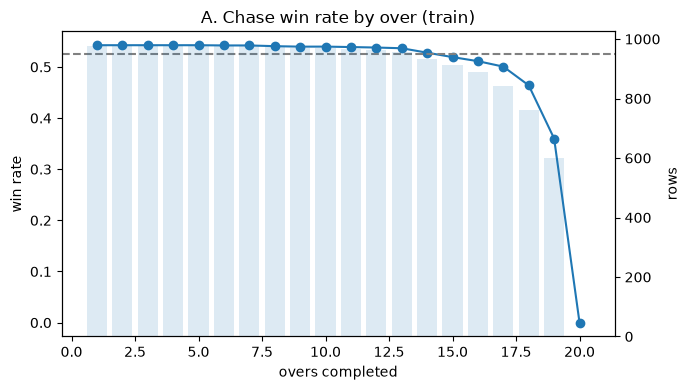

over,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
mean,0.542,0.542,0.542,0.542,0.542,0.542,0.542,0.541,0.54,0.54,0.539,0.538,0.537,0.528,0.519,0.511,0.501,0.464,0.36,0.0
size,977.000,977.000,977.000,977.000,977.000,976.000,976.000,973.000,971.00,969.00,965.000,963.000,958.000,934.000,911.000,888.000,843.000,763.000,600.00,3.0


In [28]:
g = train.groupby("over").chasing_team_won.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(g.index, g["mean"], marker="o")
ax.axhline(train.chasing_team_won.mean(), ls="--", c="gray")
ax.set(title="A. Chase win rate by over (train)", xlabel="overs completed", ylabel="win rate")
ax2 = ax.twinx(); ax2.bar(g.index, g["size"], alpha=0.15); ax2.set_ylabel("rows")
fig.tight_layout(); plt.show()
g.round(3).T

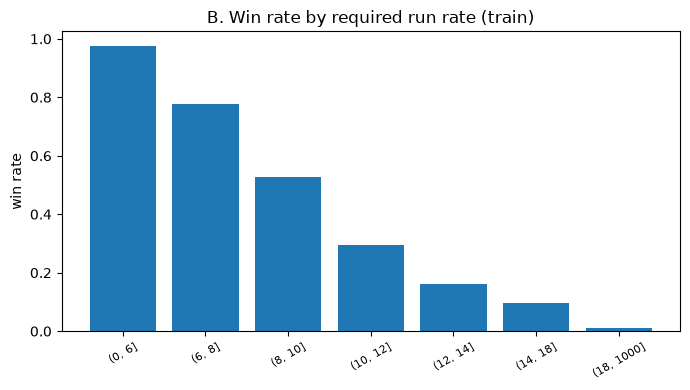

,mean,size
required_run_rate,,
"(0, 6]",0.977,2417
"(6, 8]",0.778,3773
"(8, 10]",0.527,5278
"(10, 12]",0.296,2840
"(12, 14]",0.163,1338
"(14, 18]",0.095,1007
"(18, 1000]",0.011,925


In [29]:
bins = [0, 6, 8, 10, 12, 14, 18, 1000]
b = pd.cut(train.required_run_rate, bins)
r = train.groupby(b, observed=True).chasing_team_won.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(len(r)), r["mean"])
ax.set_xticks(range(len(r))); ax.set_xticklabels([str(i) for i in r.index], rotation=30, fontsize=8)
ax.set(title="B. Win rate by required run rate (train)", ylabel="win rate")
fig.tight_layout(); plt.show()
r.round(3)

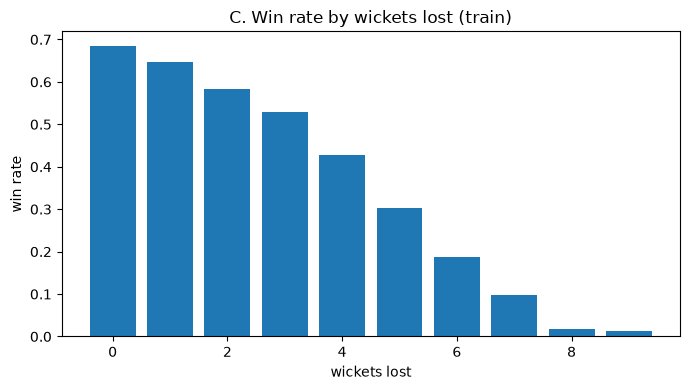

wickets_lost,0,1,2,3,4,5,6,7,8,9
mean,0.685,0.647,0.583,0.528,0.427,0.304,0.188,0.098,0.017,0.014
size,3304.000,3568.000,3220.000,2705.000,1877.000,1219.000,754.000,489.000,297.000,145.000


In [30]:
w = train.groupby("wickets_lost").chasing_team_won.agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(w.index, w["mean"])
ax.set(title="C. Win rate by wickets lost (train)", xlabel="wickets lost", ylabel="win rate")
fig.tight_layout(); plt.show()
w.round(3).T

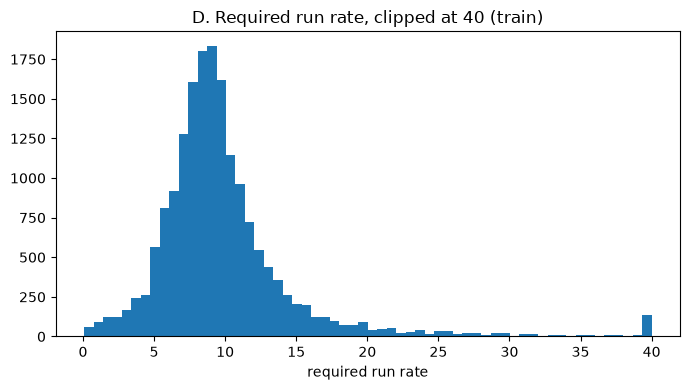

count    17578.00
mean        10.04
std          6.22
min          0.08
25%          7.29
50%          9.00
75%         11.09
max        136.00


In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(train.required_run_rate.clip(upper=40), bins=60)
ax.set(title="D. Required run rate, clipped at 40 (train)", xlabel="required run rate")
fig.tight_layout(); plt.show()
print(train.required_run_rate.describe().round(2).to_string())

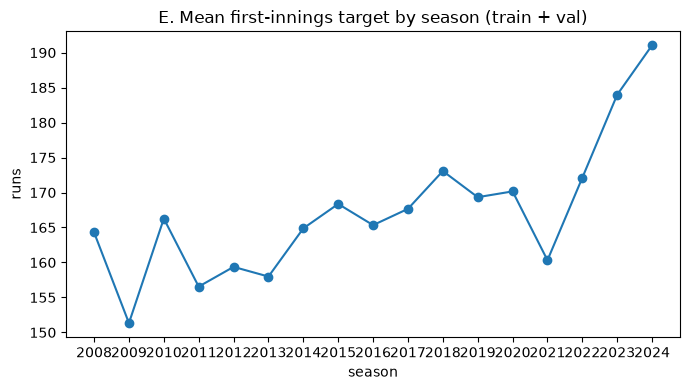

,mean_target,max_target,matches
season,,,
2008,164.3,241,54
2009,151.3,212,53
2010,166.3,247,59
2011,156.6,233,69
2012,159.4,223,73
2013,158.0,264,73
2014,164.9,232,57
2015,168.4,236,52
2016,165.3,249,56


In [32]:
s = m.groupby("season").agg(mean_target=("target", "mean"), max_target=("target", "max"), matches=("target", "size"))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(s.index, s["mean_target"], marker="o")
ax.set_xticks(list(s.index))
ax.set(title="E. Mean first-innings target by season (train + val)", xlabel="season", ylabel="runs")
fig.tight_layout(); plt.show()
s.round(1)

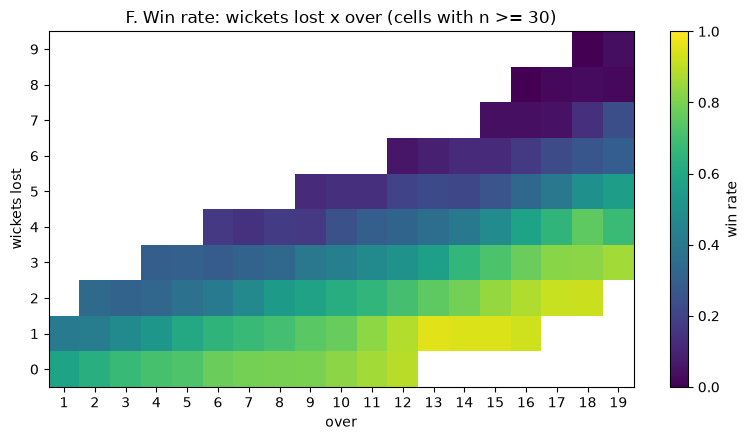

In [33]:
h = train.groupby(["wickets_lost", "over"]).chasing_team_won.agg(["mean", "size"]).reset_index()
h = h[h["size"] >= 30].pivot(index="wickets_lost", columns="over", values="mean")
fig, ax = plt.subplots(figsize=(8, 4.5))
im = ax.imshow(h.values, aspect="auto", origin="lower", vmin=0, vmax=1, cmap="viridis")
ax.set(title="F. Win rate: wickets lost x over (cells with n >= 30)", xlabel="over", ylabel="wickets lost")
ax.set_xticks(range(len(h.columns))); ax.set_xticklabels(h.columns)
ax.set_yticks(range(len(h.index))); ax.set_yticklabels(h.index)
plt.colorbar(im, ax=ax, label="win rate")
fig.tight_layout(); plt.show()

In [34]:
odd_over = ((120 - df.balls_left) - 6 * df.over) != 0
dq = pd.Series({
    "matches (train + val)": m.shape[0],
    "rows (train + val)": len(df),
    "train matches": int((m.split == "train").sum()),
    "train rows": len(train),
    "chase win rate, train, per row": round(train.chasing_team_won.mean(), 3),
    "chase win rate, train, per match": round(m[m.split == "train"].won.mean(), 3),
    "missing city (rows)": int(df.city.isna().sum()),
    "distinct venue spellings": int(df.venue.nunique()),
    "rows where legal balls != 6 x over": int(odd_over.sum()),
    "rows with required run rate > 18": int((df.required_run_rate > 18).sum()),
    "duplicate (match, over) rows": int(df.duplicated(["match_id", "over"]).sum()),
}, name="value")
dq.to_frame()

,value
matches (train + val),1047.000
rows (train + val),18817.000
train matches,977.000
train rows,17578.000
"chase win rate, train, per row",0.526
"chase win rate, train, per match",0.542
missing city (rows),870.000
distinct venue spellings,58.000
rows where legal balls != 6 x over,24.000
rows with required run rate > 18,1018.000


In [35]:
# Chase win rate per season (per match). Small seasons are noisy - look at the match counts.
ws = m.groupby("season").won.agg(chase_win_rate="mean", matches="size").round(3)
display(ws.T)

# Does the toss winner who chases win more often? (one value per match)
if "toss_won_by_chaser" in df.columns:
    tm = df.groupby("match_id").agg(toss=("toss_won_by_chaser", "first"), won=("chasing_team_won", "first"))
    display(tm.groupby("toss").won.agg(chase_win_rate="mean", matches="size").round(3))

season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
chase_win_rate,0.611,0.528,0.475,0.536,0.534,0.507,0.632,0.423,0.679,0.544,0.544,0.614,0.518,0.627,0.5,0.451,0.514
matches,54.000,53.000,59.000,69.000,73.000,73.000,57.000,52.000,56.000,57.000,57.000,57.000,56.000,59.000,74.0,71.000,70.000


,chase_win_rate,matches
toss,,
0,0.545,376
1,0.538,671
